<h1>What's Geospatial Data

Data that contains information about locations on the Earth's surface.

Examples:

Latitude
Longitude
Elevation
Roads
Buildings
Population
Land cover
Base stations
Administrative boundaries

Latitude tells us how far north or south a location is.

Longitude tells us fow far east or west a locationn is.

<h3>But there's an important issue:

Latitude and longitude are not ordinary measurements like height or population.

They're coordinates on a sphere/ellipsoid.

That matters when calculating distances.

For serious geospatial work we should use proper geographic distance calculations or project coordinates into an appropriate coordinate reference system.

<h3>GeoPandas

this is an extension of the pandas library by adding support for geospatial data

In [1]:
 #Recall that
import pandas as pd
#This gives us a data frame

In [2]:
#Since geoPandas is an extension
import geopandas as gpd
#This gives us a geo data frame


<h4>Therefore, a GeoDataframe is literally a data frame with an extra column for geometric data

That geometric data column contains info about where that object is on the earth

The Geometry colum could either be for

1. Point

A single location:

Base station,
Measurement point,
School,
Hospital

2. Line

Something with length:

Road,
Fiber route,
Transmission line

3. Polygon

An area:

LGA,
State,
Coverage zone,
Building footprint

In [3]:
#let's manually create a GPD
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

In [4]:
data = {
    "site": ["A", "B", "C"],
    "latitude": [7.29, 7.31, 7.28],
    "longitude": [5.12, 5.15, 5.10]
}

In [5]:
#Data Frame

df = pd.DataFrame(data)


In [6]:
#Geo Data Frame

<h3>before creating the geodata frame, we need to create the geometry column

In [7]:
geometry = [
    Point(lon, lat)
    for lon, lat in zip(df["longitude"], df["latitude"])
]

#The geometry column is a list, we're basically saying every "longitude" value in df is a lon n Point, same for latitude

<h3>Note that, when creating manually, gpd.DataFrame takes in the df, geometry column and CRS

In [8]:
gdf = gpd.GeoDataFrame(
    df,
    geometry = geometry,
    crs = "EPSG:4326"
)

<h4>What's EPSG:4326?


This is the coordinate reference system commonly used for:

latitude/longitude coordinates in WGS 84

Don't memorize the number just yet.

Just understand:

A CRS tells the software how to interpret the coordinates on Earth.

This becomes extremely important when calculating distances or combining geographic datasets.

<Axes: >

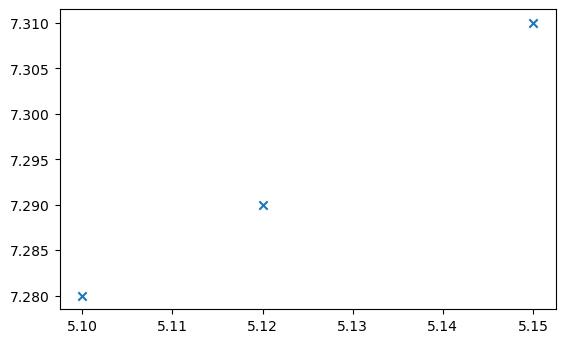

In [9]:
gdf.plot(marker = "x")

In [10]:
gdf.head()

,site,latitude,longitude,geometry
0,A,7.29,5.12,POINT (5.12 7.29)
1,B,7.31,5.15,POINT (5.15 7.31)
2,C,7.28,5.10,POINT (5.1 7.28)


In [11]:
#Pretty easy


In [12]:
#Task


In [13]:
data1 = {
    "site": ["BTS_01", "BTS_02", "BTS_03", "BTS_04", "BTS_05"],
    "latitude": [7.2900, 7.3050, 7.2800, 7.3150, 7.2700],
    "longitude": [5.1200, 5.1450, 5.1000, 5.1600, 5.1350]
}

In [14]:
#Convertr to pd

df1 = pd.DataFrame(data1)
df1.head()

,site,latitude,longitude
0,BTS_01,7.290,5.120
1,BTS_02,7.305,5.145
2,BTS_03,7.280,5.100
3,BTS_04,7.315,5.160
4,BTS_05,7.270,5.135


In [15]:
#Before converting to gpd, create geo colum

geometry1 = [
    Point(lon, lat)
    for lon, lat in zip(df1["longitude"], df1["latitude"])
]

In [16]:
gdf1  = gpd.GeoDataFrame(
    df1,   
    geometry = geometry1,
    crs = "EPSG:4326"
)
gdf1.head()

,site,latitude,longitude,geometry
0,BTS_01,7.290,5.120,POINT (5.12 7.29)
1,BTS_02,7.305,5.145,POINT (5.145 7.305)
2,BTS_03,7.280,5.100,POINT (5.1 7.28)
3,BTS_04,7.315,5.160,POINT (5.16 7.315)
4,BTS_05,7.270,5.135,POINT (5.135 7.27)


<Axes: >

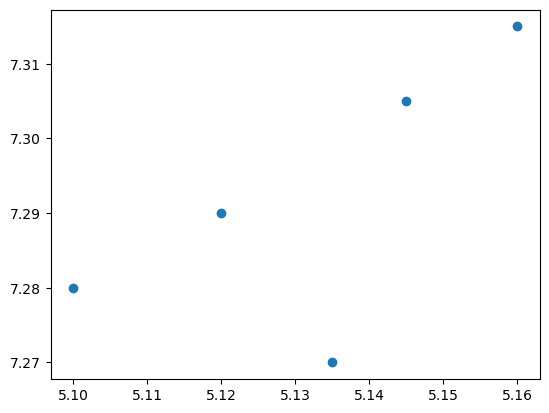

In [17]:
gdf1.plot()